# Fluopy plot gallery

Developer notebook for visually reviewing the built-in plots. Run all cells
from top to bottom after changing plotting code.

The examples use real Fluopy objects.
The synthetic arrays near the end exercise the shared plotting helper.

The gallery shows each public plotting method and each Blinking.plot mode.
It is a visual review aid, not a numerical validation or a parameter sweep.

In [1]:
import platform
from dataclasses import replace

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, poisson

import fluopy
from fluopy import analysis as an
from fluopy import blinking as bl
from fluopy import emissions as em
from fluopy import fcs
from fluopy import fluo_data as fd
from fluopy import fluorophores as fl
from fluopy import plotting as pl
from fluopy import prediction as pr
from fluopy import simulation as si
from fluopy import transitions as tr

%matplotlib inline

pd.Series(
    {
        "Python": platform.python_version(),
        "Fluopy": fluopy.__version__,
        "Matplotlib": mpl.__version__,
    }
)

Python                        3.12.10
Fluopy        0.4.0.dev243+gdca2671ee
Matplotlib                     3.11.2
dtype: str

## Shared single-fluorophore model

The built-in Cy5 model supplies excitation, emission, triplet, and cis-state
dynamics. Analysis and Prediction share the same TransitionSet. Their plots
below use the package's default font sizes, tick styling, and labels.

In [2]:
dye = fl.Fluorophore("cy5_dna", [0, 0])
single_system = fl.FluorophoreSystem([dye])
single_model = tr.TransitionSet(
    single_system.load_transitions(
        irradiance=2,
        wavelength=640,
        bleaching=False,
        energy_transfer=False,
        dstorm=False,
    ),
    single_system,
).finalize()
single_simulation = si.Simulation(single_model)
single_simulation.run(size=80_000, seed=101, warn_precision=False)
analysis = an.Analysis(single_simulation)
prediction = pr.Prediction(single_model)
emitting_id = single_model.transition_df.loc[
    single_model.transition_df["photon"]
].index.get_level_values(1)[0]

pd.Series(
    {
        "Events": single_simulation.transition_series.size,
        "Duration (s)": single_simulation.time_series[-1],
        "States": len(single_model.single_states["cy5_dna"]),
    }
)

Events          80000.000000
Duration (s)        0.027483
States              4.000000
dtype: float64

## Model graphs

TransitionSet.plot draws the transition network. FluorophoreSystem.plot
draws molecular positions; a paired system appears later in the gallery.

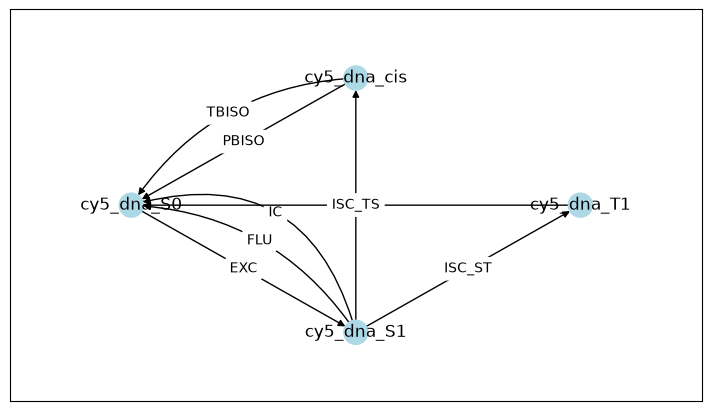

In [3]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
single_model.plot(axes=[ax])
plt.show()

## Analysis and Prediction: summary plots

The left column shows simulation statistics with prediction markers. The
right column calls the matching Prediction method directly.

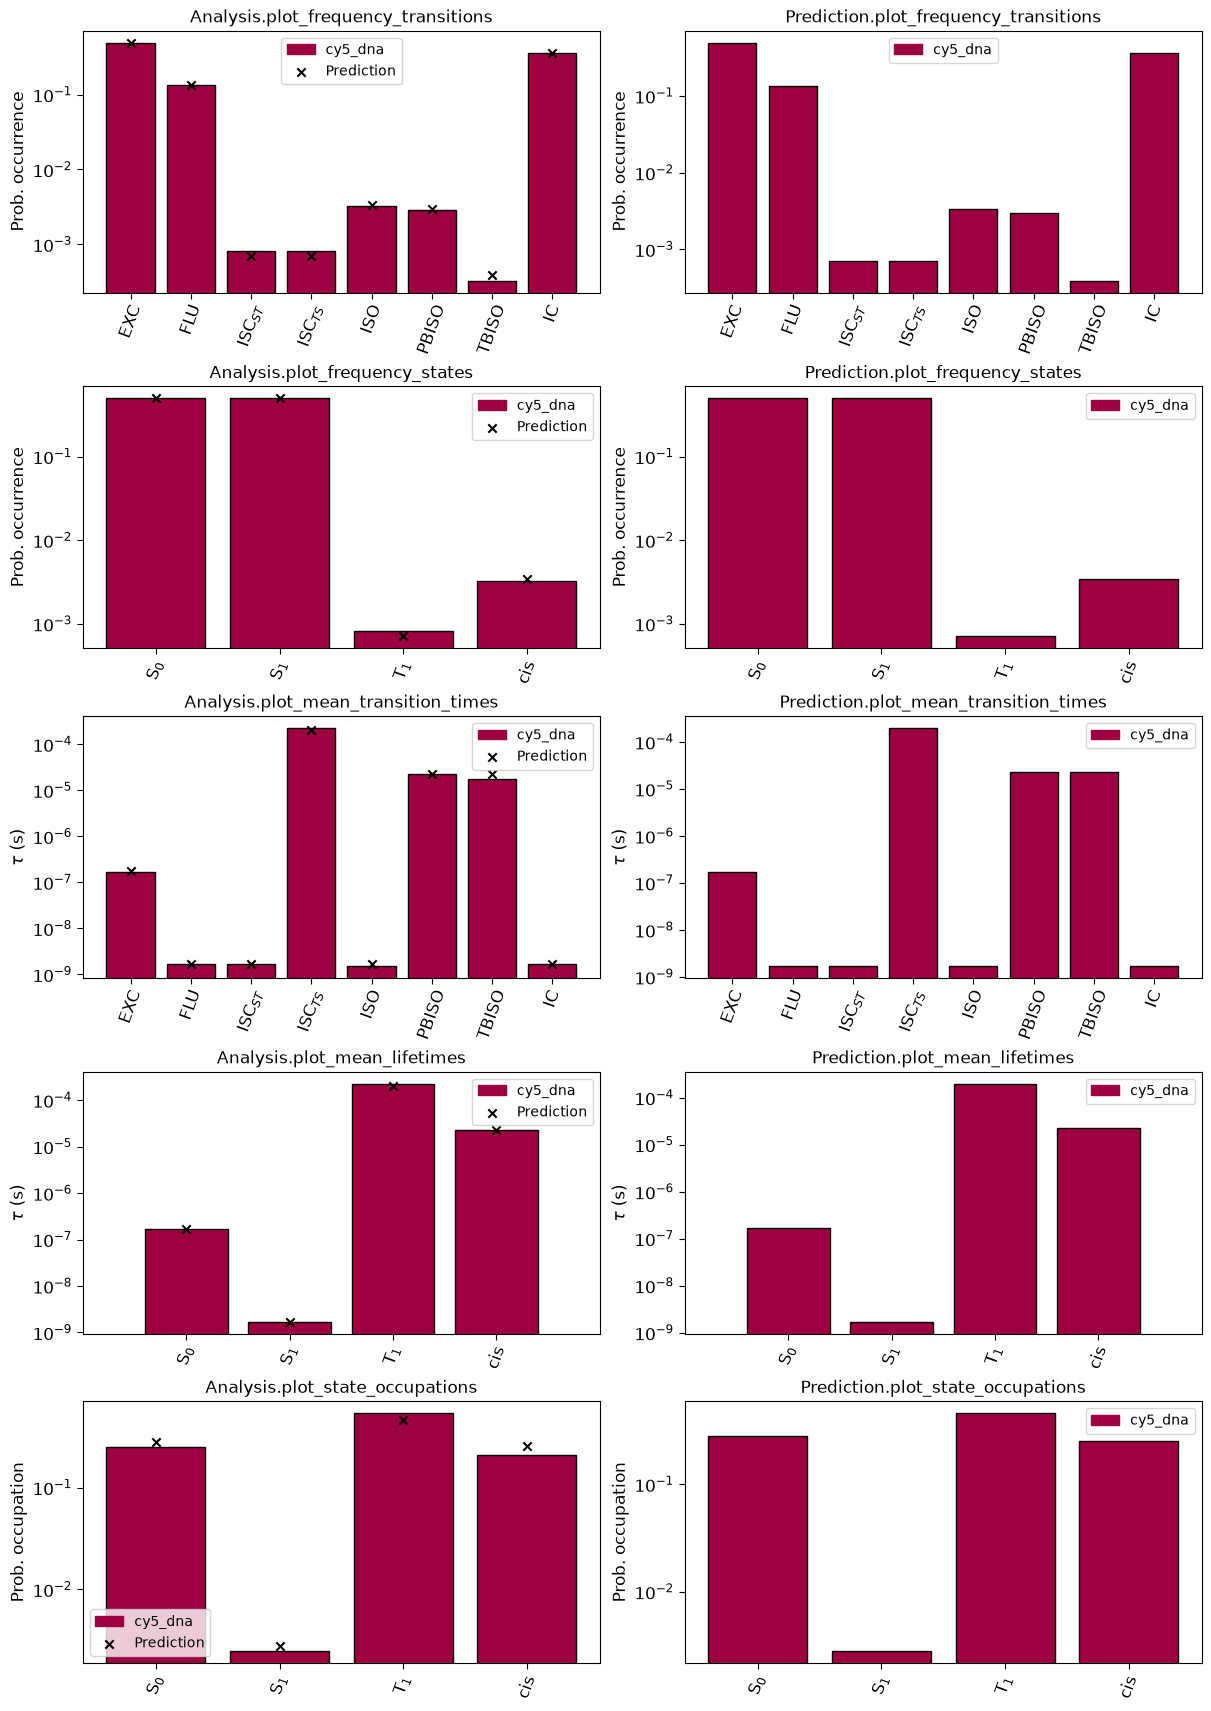

In [4]:
summary_methods = [
    "plot_frequency_transitions",
    "plot_frequency_states",
    "plot_mean_transition_times",
    "plot_mean_lifetimes",
    "plot_state_occupations",
]
fig, axes = plt.subplots(5, 2, figsize=(12, 17), layout="constrained")
for row, method in enumerate(summary_methods):
    getattr(analysis, method)(prediction=prediction, ax=axes[row, 0])
    getattr(prediction, method)(ax=axes[row, 1])
    axes[row, 0].set_title(f"Analysis.{method}")
    axes[row, 1].set_title(f"Prediction.{method}")
plt.show()

## Lifetime and transition-time distributions

These four panels cover both distribution methods on Analysis and Prediction.
Simulation histograms include the predicted density.

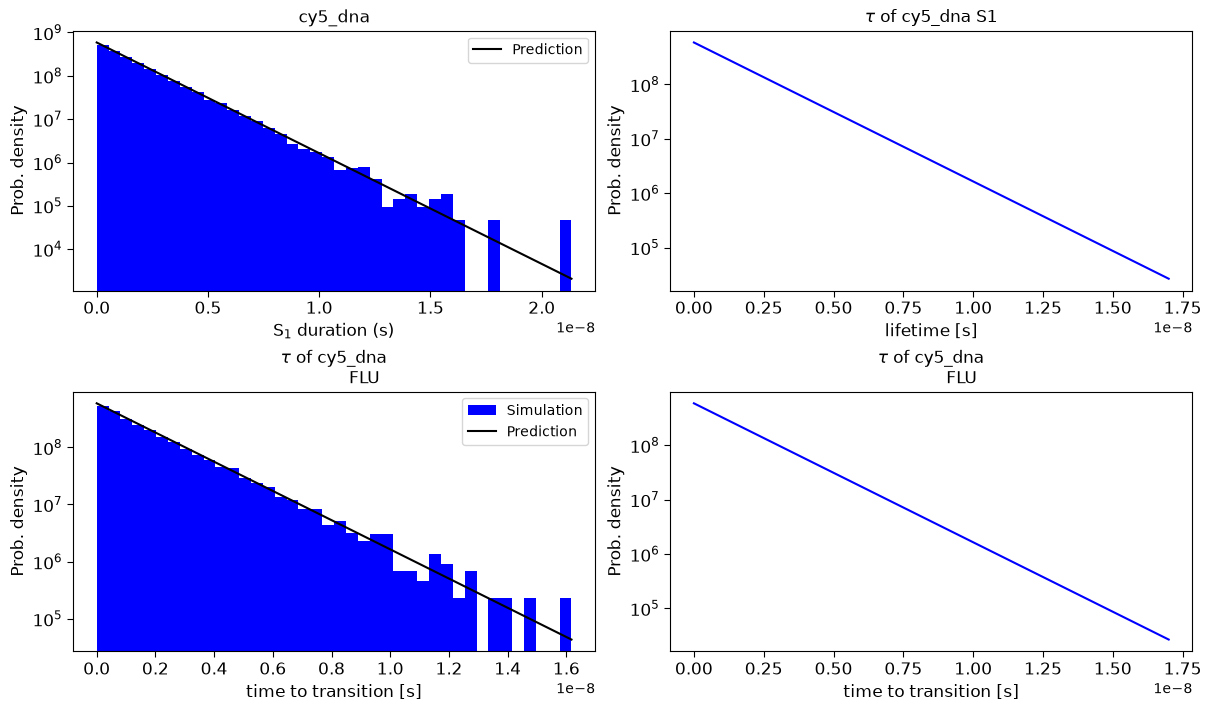

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
analysis.plot_lifetime_distributions(
    "cy5_dna",
    tr.SingleState.S1.value,
    prediction=prediction,
    bins=40,
    ax=axes[0, 0],
)
prediction.plot_lifetime_distributions(
    "cy5_dna",
    tr.SingleState.S1.value,
    ax=axes[0, 1],
)
analysis.plot_transition_time_distributions(
    "cy5_dna",
    emitting_id,
    prediction=prediction,
    bins=40,
    ax=axes[1, 0],
)
prediction.plot_transition_time_distributions(
    "cy5_dna",
    emitting_id,
    ax=axes[1, 1],
)
plt.show()

## Standalone figure and explicit overrides

The first call lets Fluopy create and lay out its own figure. The second
overlays state frequencies on an existing axis with an explicit font size,
marker size, and tick parameters.

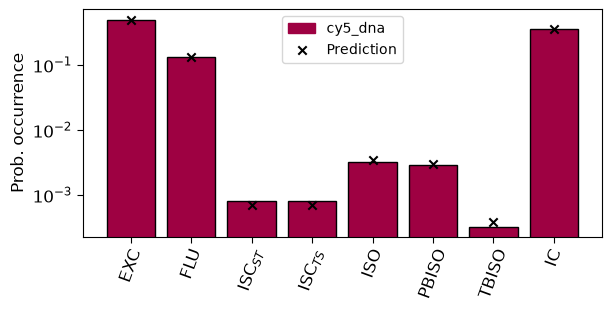

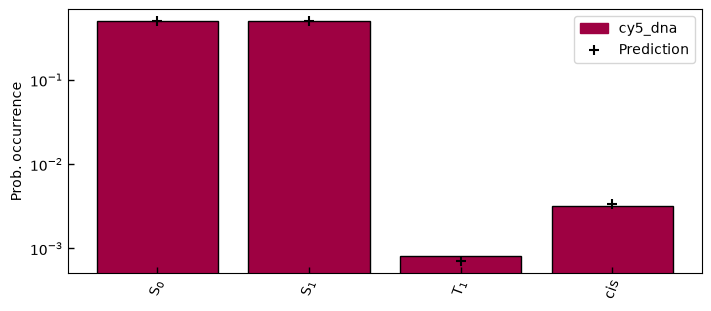

In [6]:
analysis.plot_frequency_transitions(prediction=prediction)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
analysis.plot_frequency_states(
    prediction=prediction,
    ax=ax,
    fontsize=10,
    tick_params={"direction": "in", "width": 1},
    draw_marker_param={"marker": "+", "color": "black", "s": 50},
)
plt.show()

## Interacting fluorophores

A donor and acceptor provide paired transition labels and several legend
groups. Only S0 absorption is retained to keep this visual example compact.
Paired Prediction supports frequencies, so the two comparisons use those
statistics. The graph figure includes single and paired transition groups.

Only frequencies are available for systems with paired transitions; lifetimes and occupations are not available.


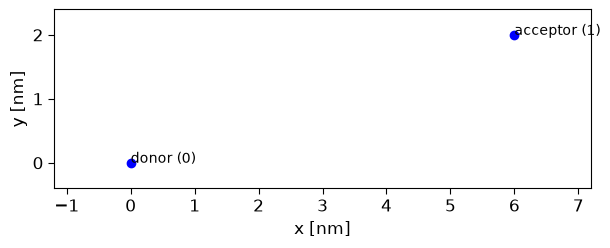

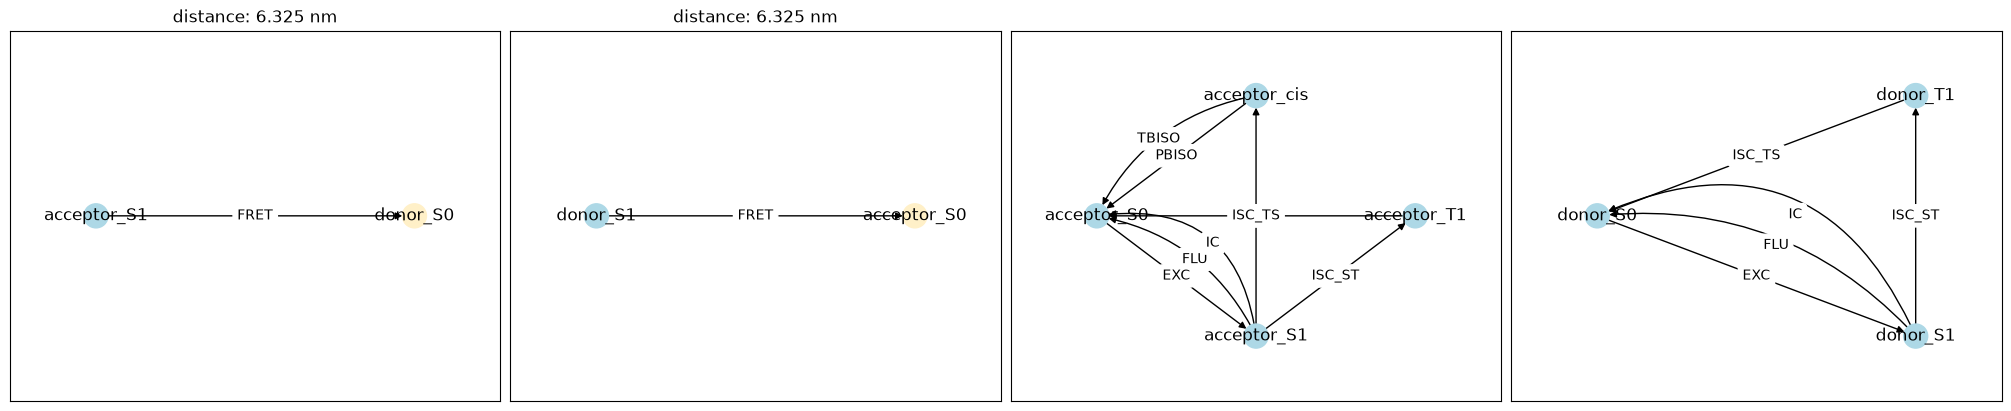

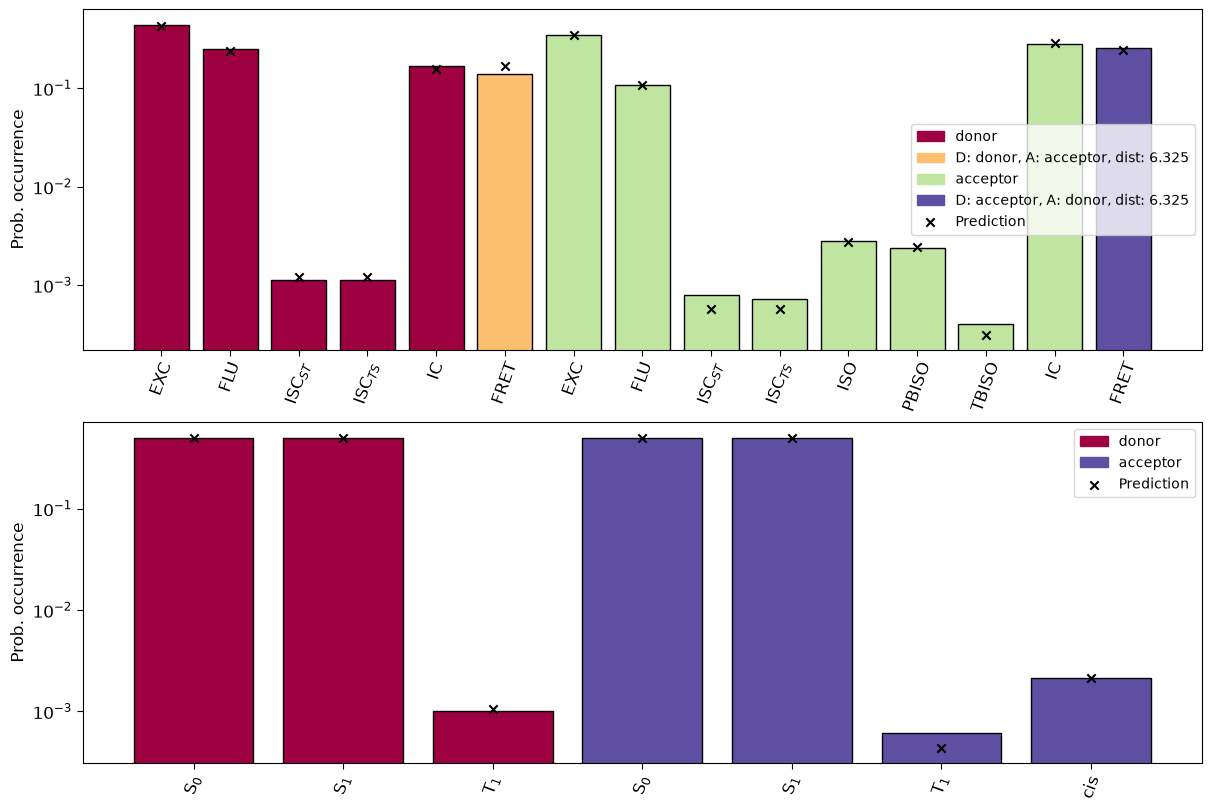

In [7]:
donor_data = replace(
    fd.atto643, absorption_spectra={"s0": fd.atto643.absorption_spectra["s0"]}
)
acceptor_data = replace(
    fd.cy5_dna, absorption_spectra={"s0": fd.cy5_dna.absorption_spectra["s0"]}
)
paired_system = fl.FluorophoreSystem(
    [
        fl.Fluorophore("donor", [0, 0], constants=donor_data),
        fl.Fluorophore("acceptor", [6, 2], constants=acceptor_data),
    ]
)
paired_model = tr.TransitionSet(
    paired_system.load_transitions(
        irradiance=2,
        wavelength=640,
        energy_transfer=True,
        bleaching=False,
        dstorm=False,
    ),
    paired_system,
).finalize()
paired_simulation = si.Simulation(paired_model)
paired_simulation.run(size=40_000, seed=102, warn_precision=False)
paired_analysis = an.Analysis(paired_simulation)
paired_prediction = pr.Prediction(paired_model)

paired_system.plot()
plt.show()

graph_count = paired_model.transition_df.index.get_level_values(0).nunique()
fig, axes = plt.subplots(
    1,
    graph_count,
    figsize=(5 * graph_count, 4),
    layout="constrained",
    squeeze=False,
)
paired_model.plot(axes=axes.ravel())
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
paired_analysis.plot_frequency_transitions(prediction=paired_prediction, ax=axes[0])
paired_analysis.plot_frequency_states(prediction=paired_prediction, ax=axes[1])
plt.show()

## Detected photons

Two wavelength channels collect photons from the single-fluorophore
simulation. Each Emissions plotting method is shown: the default line trace,
an optional step trace, cumulative events, and count histograms with means.

The trace panels show the first 2 ms; cumulative events and histograms use the
full simulated record.

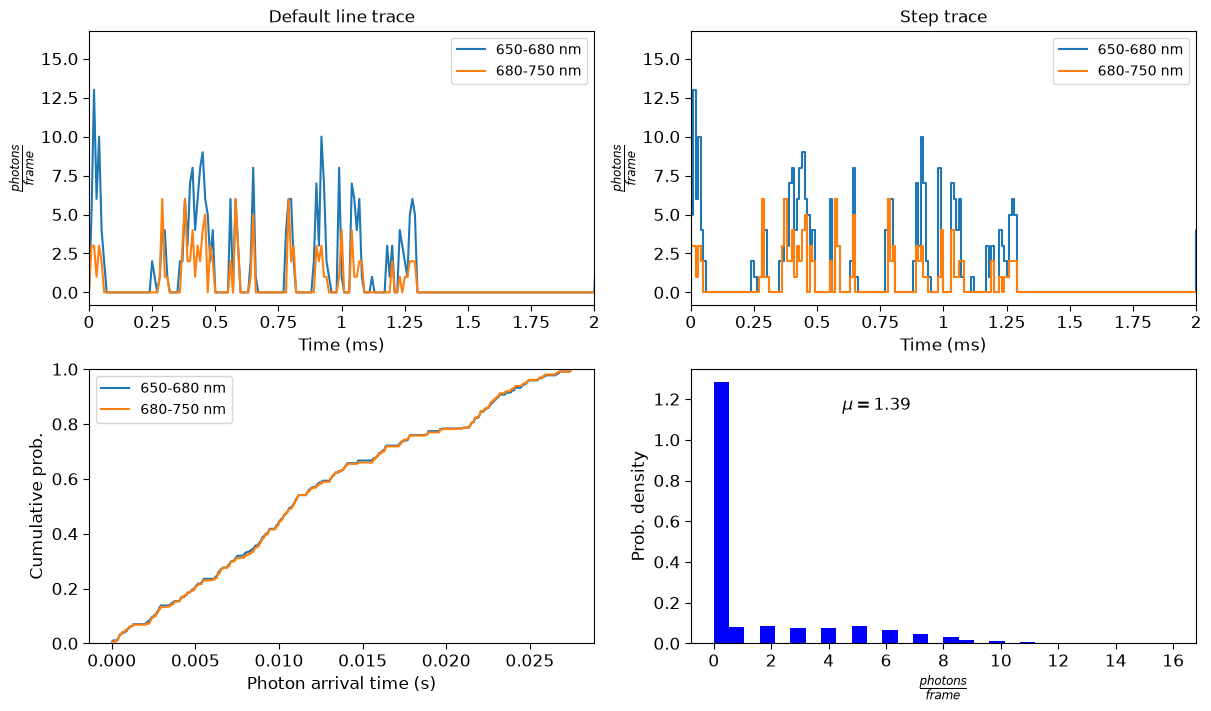

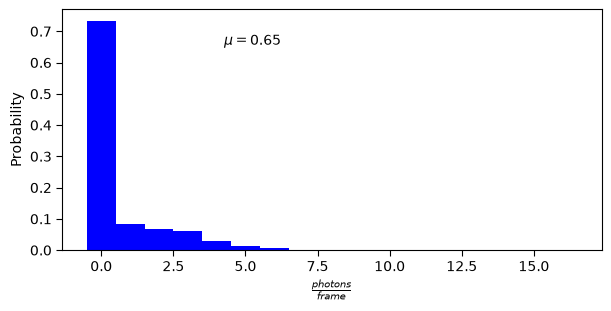

In [8]:
channels = {
    "650-680 nm": em.DetectionChannel((650, 680), detection_efficiency=0.7),
    "680-750 nm": em.DetectionChannel((680, 750), detection_efficiency=0.5),
}
photons = em.Emissions(frame_time="10us", channels=channels, seed=103)
photons.extract(single_simulation)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for index, channel in enumerate(channels):
    options = dict(channel=channel, color=f"C{index}", label=channel, legend=True)
    photons.plot_time_series(
        ax=axes[0, 0],
        xlim=(0, 2e-3),
        adjust_x=1e3,
        xlabel="Time (ms)",
        **options,
    )
    photons.plot_time_series(
        ax=axes[0, 1],
        type_="step",
        where="pre",
        xlim=(0, 2e-3),
        adjust_x=1e3,
        xlabel="Time (ms)",
        **options,
    )
    photons.plot_cumulative_events(ax=axes[1, 0], **options)
photons.plot_histogram(
    channel="650-680 nm",
    include_0=True,
    display_mean=True,
    bins=30,
    ax=axes[1, 1],
)
axes[0, 0].set_title("Default line trace")
axes[0, 1].set_title("Step trace")
plt.show()

photons.plot_histogram(
    channel="680-750 nm",
    density=False,
    include_0=True,
    display_mean=True,
    bins=np.arange(-0.5, photons.event_time_series.max().max() + 1.5),
    fontsize=10,
)
plt.show()

## Blinking plots

All six Blinking.plot modes use periods derived from detected photons. The
histograms and boxplots use milliseconds; frame-series plots retain their
default units. The final binary trace comes directly from the simulated
triplet and cis states and exercises blinking.plot_off_statistics.

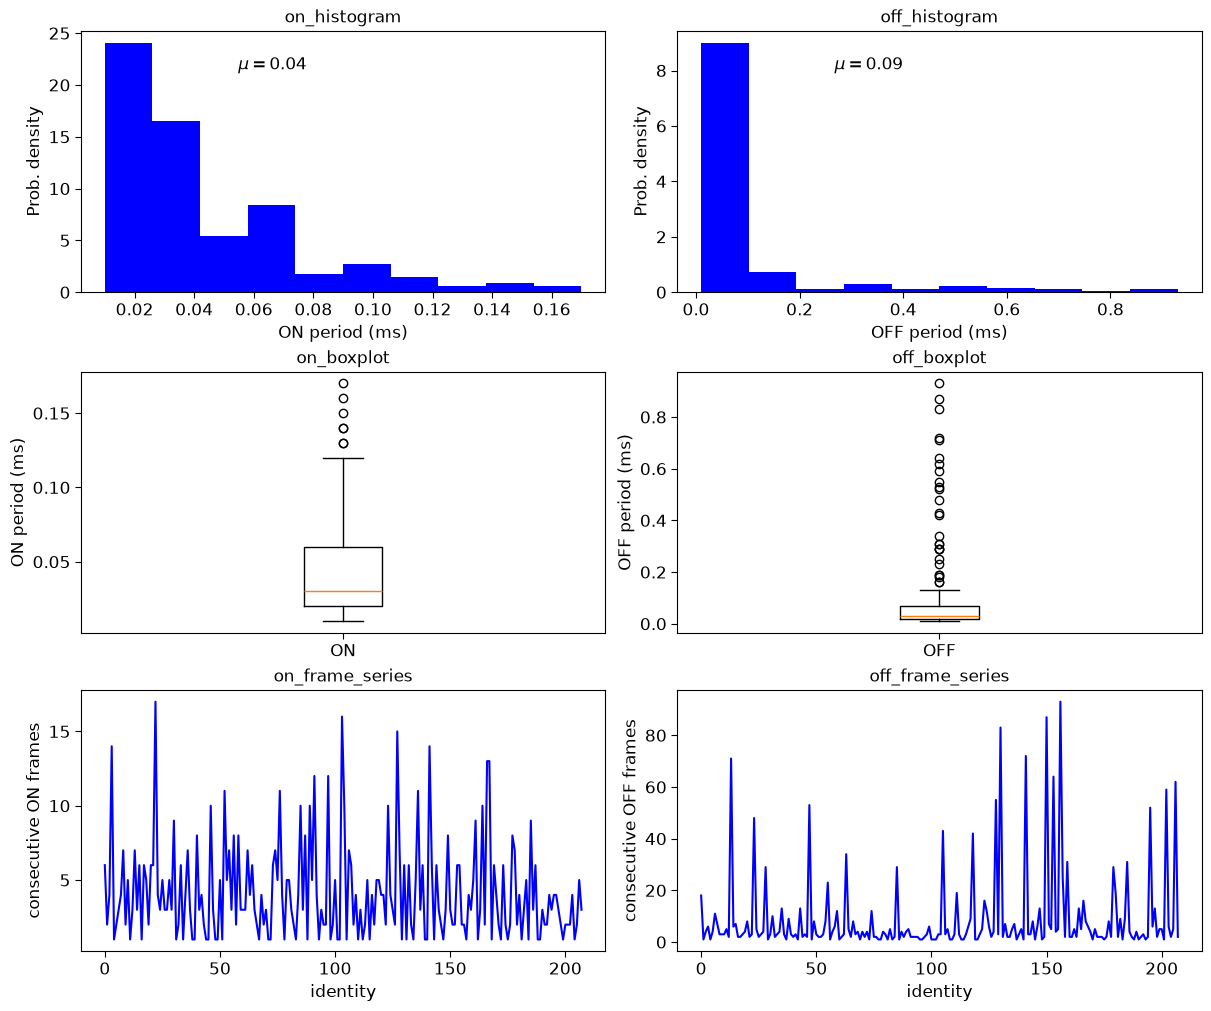

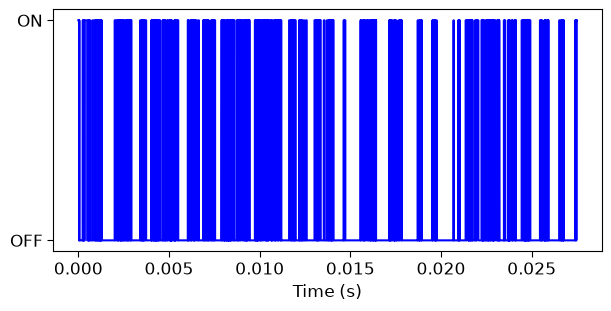

In [9]:
blinking = bl.Blinking(photons, channel="650-680 nm", threshold=0)
modes = [
    "on_histogram",
    "off_histogram",
    "on_boxplot",
    "off_boxplot",
    "on_frame_series",
    "off_frame_series",
]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for ax, mode in zip(axes.ravel(), modes):
    options = {"as_time": "ms"} if "frame_series" not in mode else {}
    blinking.plot(mode, ax=ax, title=mode, **options)
plt.show()

off_times, off_values = bl.get_off_statistics(
    single_simulation, index=0, dark_states=(tr.SingleState.T1, tr.SingleState.cis)
)
bl.plot_off_statistics(off_times, off_values)
plt.show()

## Correlation plots

FCS.plot uses the shared Fluopy plotting helper; FCS.plot_matplotlib uses
Matplotlib directly. Both display the same computed correlation so their
appearance can be compared. The second figure overlays both channels.

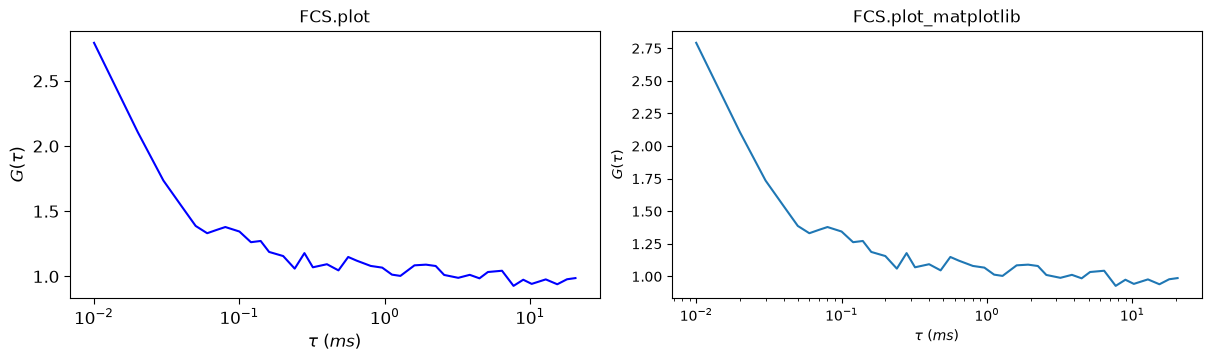

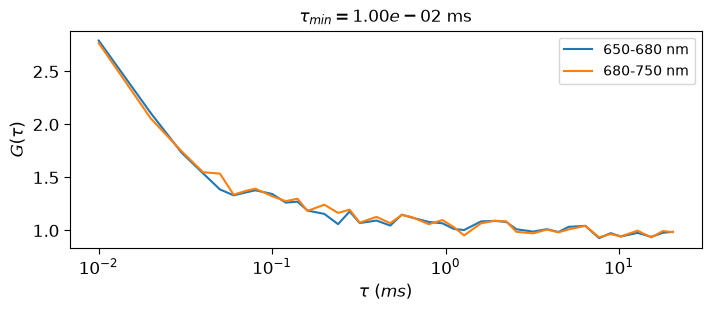

In [10]:
correlation = fcs.FCS(photons, channel="650-680 nm")
correlation.autocorrelate_time_series(m=8)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
correlation.plot(unit="ms", ax=axes[0])
correlation.plot_matplotlib(unit="ms", ax=axes[1])
axes[0].set_title("FCS.plot")
axes[1].set_title("FCS.plot_matplotlib")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for index, channel in enumerate(channels):
    channel_correlation = fcs.FCS(photons, channel=channel)
    channel_correlation.autocorrelate_time_series(m=8)
    channel_correlation.plot(
        unit="ms",
        ax=ax,
        color=f"C{index}",
        label=channel,
        legend=True,
    )
plt.show()

## Shared helper: lines, points, steps, and uncertainty

Synthetic arrays exercise plot_data's line, multiple_line, scatter, errorbar,
step, and stair types. The final cell below covers the remaining plot types.
The scientific-notation example also exercises top and right secondary axes.

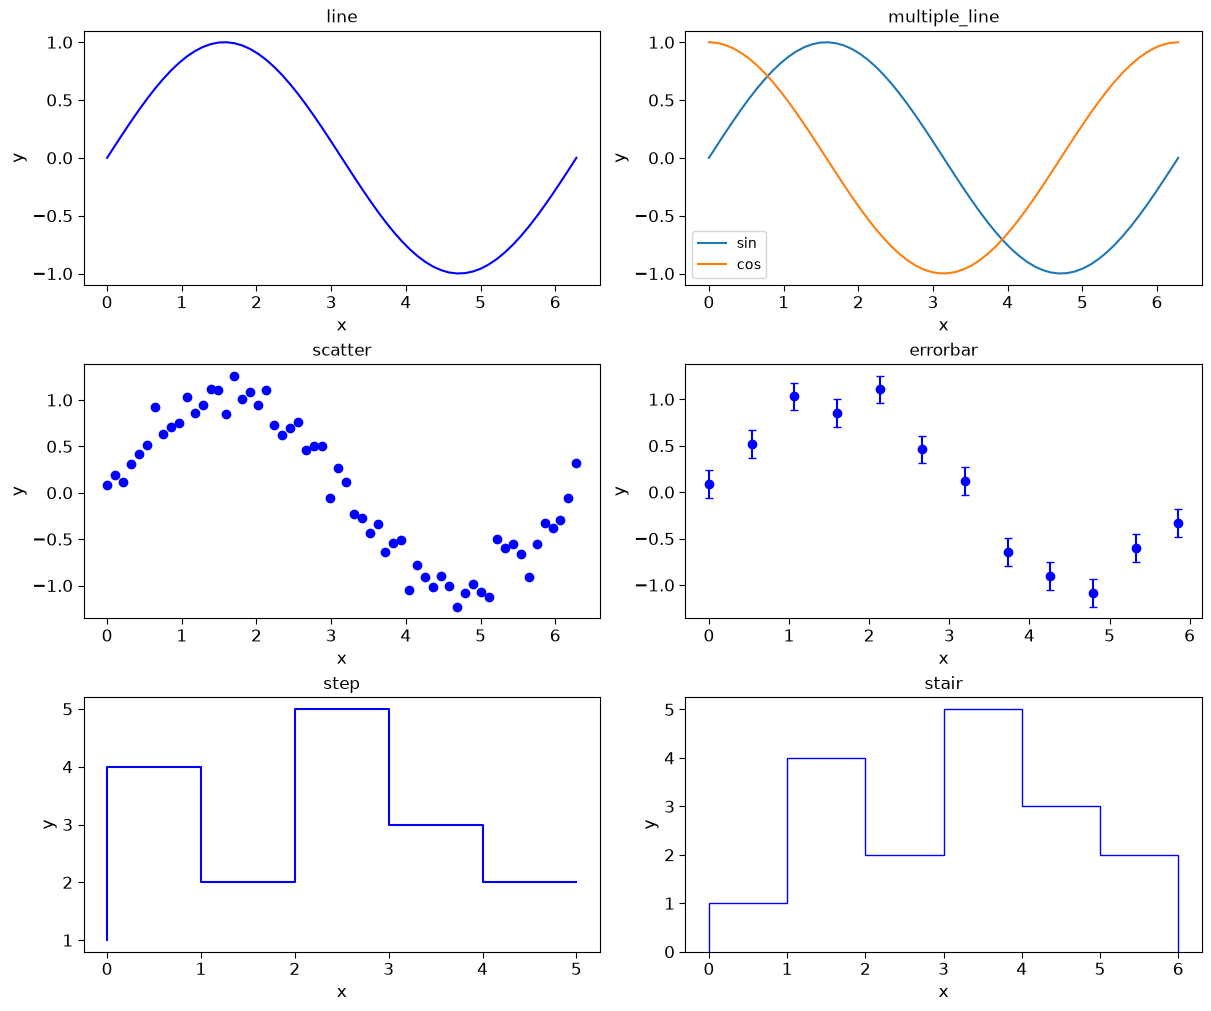

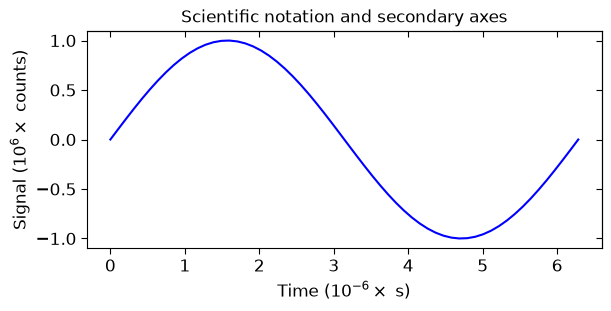

In [11]:
rng = np.random.default_rng(104)
x = np.linspace(0, 2 * np.pi, 60)
y = np.sin(x)
noisy = y + rng.normal(0, 0.15, x.size)
edges = np.arange(7)
values = np.array([1, 4, 2, 5, 3, 2])

fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
pl.plot_data(data=[x, y], ax=axes[0, 0], title="line")
pl.plot_data(
    type_="multiple_line",
    data=[[x, y], [x, np.cos(x)]],
    label=["sin", "cos"],
    color=["C0", "C1"],
    legend=True,
    ax=axes[0, 1],
    title="multiple_line",
)
pl.plot_data(type_="scatter", data=[x, noisy], ax=axes[1, 0], title="scatter")
pl.plot_data(
    type_="errorbar",
    data=[x[::5], noisy[::5], np.full(12, 0.15)],
    fmt="o",
    capsize=3,
    ax=axes[1, 1],
    title="errorbar",
)
pl.plot_data(type_="step", data=[edges[:-1], values], ax=axes[2, 0], title="step")
pl.plot_data(type_="stair", data=[edges, values], ax=axes[2, 1], title="stair")
plt.show()

pl.plot_data(
    data=[x * 1e-6, y * 1e6],
    xlabel="Time (s)",
    ylabel="Signal (counts)",
    tick_style_x="sci",
    tick_style_y="sci",
    second_axis_x=True,
    second_axis_y=True,
    title="Scientific notation and secondary axes",
)
plt.show()

## Shared helper: histograms, bars, and boxplots

These panels cover hist, multiple_hist, 2d_hist, bar, and boxplot. Continuous
and discrete distribution overlays exercise both density helpers.

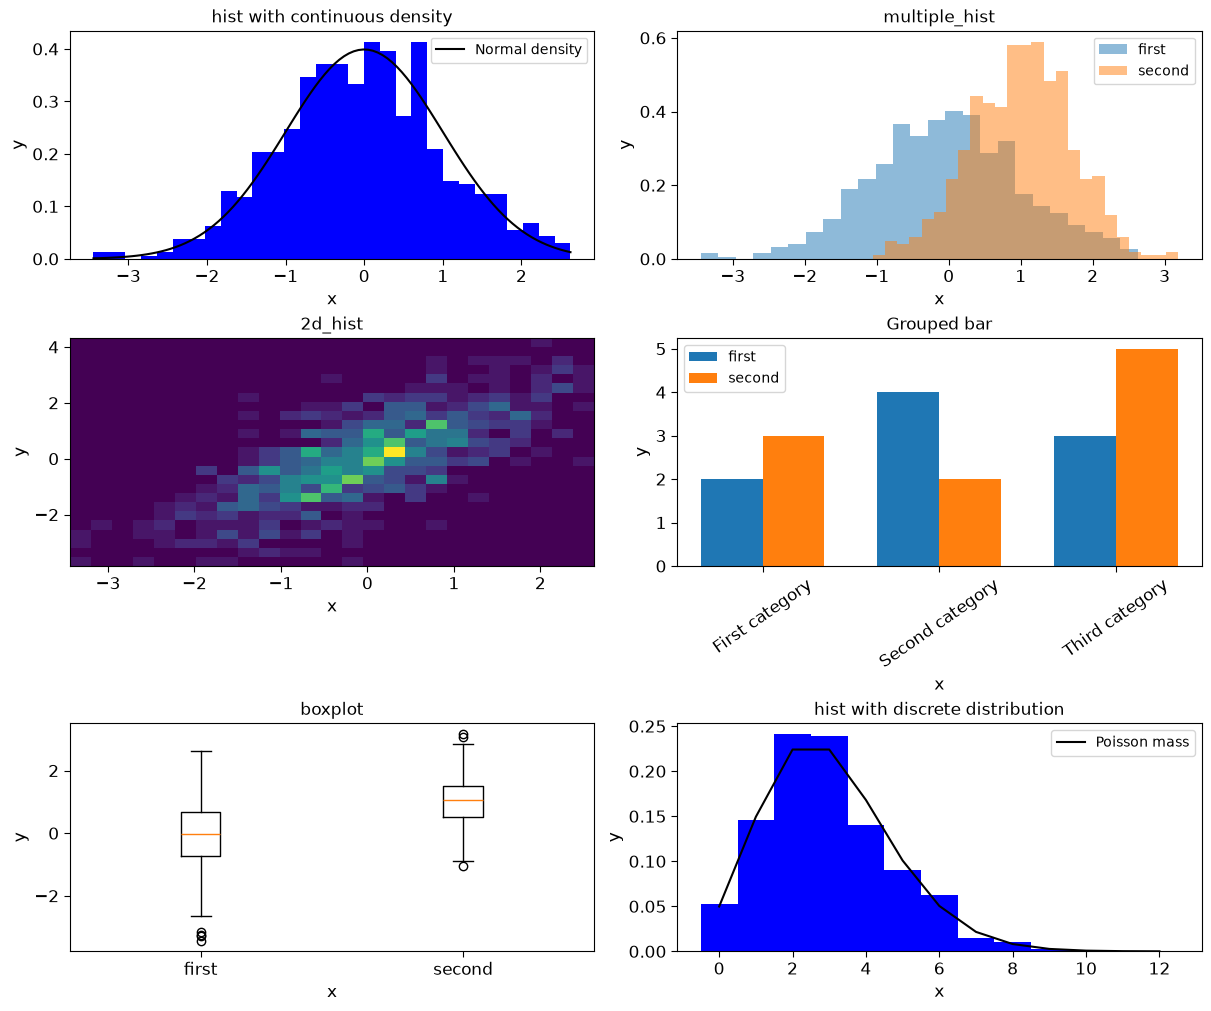

In [12]:
normal_samples = rng.normal(size=800)
shifted_samples = rng.normal(1, 0.7, 600)
poisson_samples = rng.poisson(3, 800)
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
pl.plot_data(
    type_="hist",
    data=normal_samples,
    bins=30,
    density=True,
    plot_distribution=norm(),
    plot_distribution_label="Normal density",
    legend=True,
    ax=axes[0, 0],
    title="hist with continuous density",
)
pl.plot_data(
    type_="multiple_hist",
    data=[normal_samples, shifted_samples],
    bins=25,
    density=True,
    alpha=0.5,
    label=["first", "second"],
    color=["C0", "C1"],
    legend=True,
    ax=axes[0, 1],
    title="multiple_hist",
)
pl.plot_data(
    type_="2d_hist",
    data=[normal_samples, normal_samples + rng.normal(size=800)],
    bins=25,
    ax=axes[1, 0],
    title="2d_hist",
)
pl.plot_data(
    type_="bar",
    data=[[0, 1, 2], [[2, 4, 3], [3, 2, 5]]],
    width=0.35,
    label=["first", "second"],
    color=["C0", "C1"],
    legend=True,
    xticks=[0.175, 1.175, 2.175],
    xticklabels={
        "labels": ["First category", "Second category", "Third category"],
        "rotation": 35,
    },
    ax=axes[1, 1],
    title="Grouped bar",
)
pl.plot_data(
    type_="boxplot",
    data=[normal_samples, shifted_samples],
    label=["first", "second"],
    ax=axes[2, 0],
    title="boxplot",
)
pl.plot_data(
    type_="hist",
    data=poisson_samples,
    bins=np.arange(-0.5, 13.5),
    density=True,
    plot_distribution=poisson(3),
    plot_distribution_label="Poisson mass",
    legend=True,
    ax=axes[2, 1],
    title="hist with discrete distribution",
)
plt.show()

## Figure utilities

The auxiliary create_row_subtitles and add_table helpers are also available
in fluopy.plotting. This small figure checks their text and positioning.

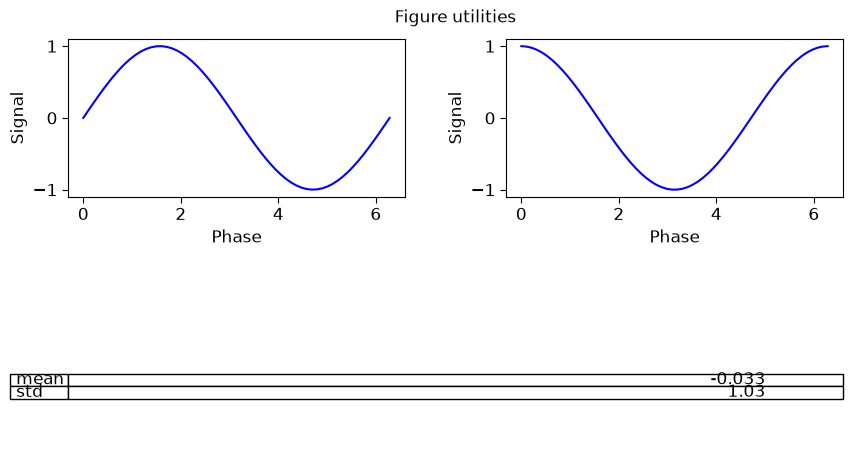

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
pl.plot_data(data=[x, y], ax=axes[0, 0], xlabel="Phase", ylabel="Signal")
pl.plot_data(data=[x, np.cos(x)], ax=axes[0, 1], xlabel="Phase", ylabel="Signal")
pl.delete_subplots(axes, keep_number=2)
pl.add_table(
    axes[0, 0],
    pd.Series({"mean": normal_samples.mean(), "std": normal_samples.std()}).round(3),
    grid=212,
)
pl.create_row_subtitles(axes[:1], nrows=1, ncols=2, titles=["Figure utilities"])
fig.subplots_adjust(top=0.82, hspace=0.7, wspace=0.3)
plt.show()